# PCA baseline on B0

This notebook draws the PCA baseline: how the model sees a service, how it raises and explains an alarm, and what it finds on the test fold.

Every number comes from `anomaly.models.evaluate.compute`, the same frozen protocol that writes `results/pca-B0/<app>/`: nothing here is tuned or chosen. Set `APP` (`"hotel"` or `"social"`) and, if you like, `EXAMPLE` (a test fault run) and `SERVICE`, then run all cells.

- Figures 1-2: the model, one PCA per service.
- Figures 3-5: one test fault run, from the injection to the explained alarm.
- Figures 6-8: the test fold. Dev faults are left out of every figure: they only tune choices.

Terms used in the figures:
- **score**: the SPE (squared residual outside the healthy subspace), persistent over 2 steps;
- **score / threshold**: above 1, the service is in alarm;
- **rules**: restart (a service that restarts) and absence (a sample group present in training is missing);
- **reference system**: the model with both rules, `model+restart+absence`; `model` and `model+restart` are its ablations.

In [13]:
import sys
import warnings
from pathlib import Path

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "anomaly" / "build.py").exists())
sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from anomaly import build, inputs
from anomaly.models import evaluate as ev, pca

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200, "display.max_columns", 40)

APP = "social"  # "hotel" or "social"
DATA = build.DATASET / "built"
# The test fault run of figures 3-5, and the service figures 2-3 follow (None: the first ranked at the first alarm)
EXAMPLE = {"hotel": "test/network_loss_hotel_res__r1", "social": "test/port_misconfig_user_social_network__r1"}[APP]
SERVICE = None

res = ev.compute("pca", APP, DATA)
RUNS = {r.id: r for r in res.runs}
SERVICES = res.runs[0].services
FEATURES = res.model.features
FULL = ev.VARIANTS[-1]  # the reference system
print(f"{APP}: {len(res.runs)} runs, {len(SERVICES)} services, reference system {FULL}")

social: 57 runs, 26 services, reference system model+restart+absence


In [15]:
# Colours: categorical slots in a fixed order; blue-grey-red centred on the threshold for score / threshold
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, YELLOW, RED, NEUTRAL = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948", "#f0efec"
VARIANT_COLOUR = dict(zip(ev.VARIANTS, (BLUE, ORANGE, AQUA)))
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": INK2,
    "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False, "lines.linewidth": 2,
    "figure.dpi": 110})


def minutes(r):
    """Minutes from the injection (fault and noop runs) or from the first step (clean sessions)."""
    return (r.t - (r.t_inject or r.t[0])) / 60


def first_alarm(r, v=FULL):
    """Step of the first alarm that starts after the injection, or None."""
    first = ev.starts(r.alarm[v]).any(1) & r.fault
    return int(first.argmax()) if first.any() else None


r = RUNS[EXAMPLE]
k = first_alarm(r)
order = ev.rank(r.norm[k], r.rule[FULL][k])
SVC = SERVICES.index(SERVICE) if SERVICE else int(order[0])
print(f"{EXAMPLE}: target {[SERVICES[i] for i in r.targets]}, first alarm {minutes(r)[k]:.1f} min after the injection, "
      f"first ranked {SERVICES[order[0]]}; figures 2-3 follow {SERVICES[SVC]}")

test/port_misconfig_user_social_network__r1: target ['user-service'], first alarm 1.0 min after the injection, first ranked compose-post-service; figures 2-3 follow compose-post-service


## 1. How many directions a healthy service needs

**What is plotted.** Left: for each service, the share of its healthy variance explained by the first k principal directions (the cumulative squared singular values of its standardized training matrix); the dot is the k the model keeps, the first that reaches 95%. Right: that k per service.

**How to read it.** A service whose curve reaches 95% with few directions moves in a low-dimensional way when healthy: its metrics change together, mostly with the load. Everything outside those k directions is what the score measures.

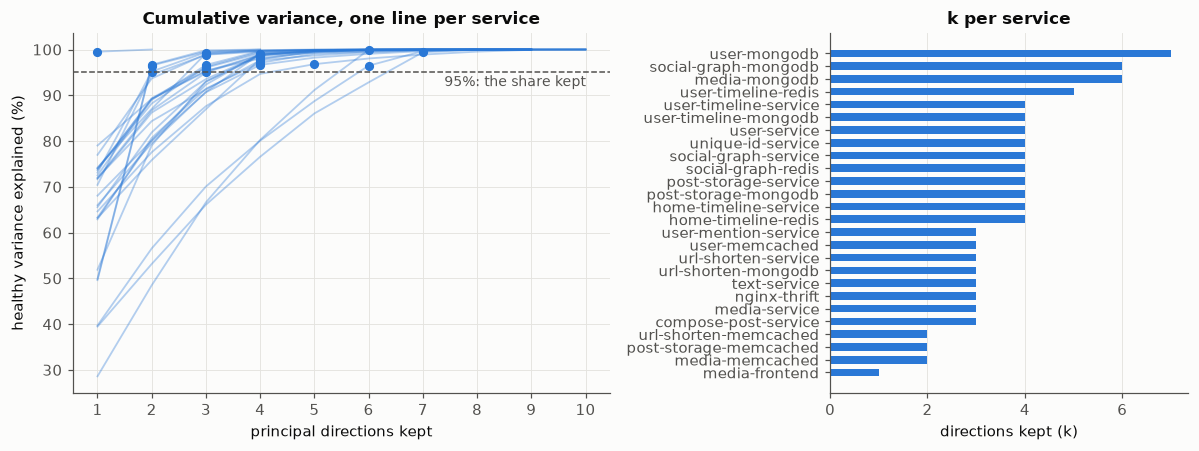

In [16]:
cards = [(s, m) for s, m in zip(SERVICES, res.model.services) if m is not None]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [3, 2]})
for s, m in cards:
    c = 100 * m.cumulative
    a1.plot(np.arange(1, len(c) + 1), c, color=BLUE, alpha=.35, lw=1.2)
    kk = m.V.shape[1]
    a1.plot(kk, c[kk - 1], "o", color=BLUE, ms=5)
a1.axhline(100 * pca.VAR, color=INK2, ls="--", lw=1)
a1.text(len(FEATURES), 100 * pca.VAR - 3, "95%: the share kept", color=INK2, fontsize=9, ha="right")
a1.set(xlabel="principal directions kept", ylabel="healthy variance explained (%)",
       title="Cumulative variance, one line per service", xticks=range(1, len(FEATURES) + 1))
ks = sorted((m.V.shape[1], s) for s, m in cards)
a2.barh([s for _, s in ks], [kk for kk, _ in ks], color=BLUE, height=.6)
a2.set(xlabel="directions kept (k)", title="k per service")
a2.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

## 2. Moving along the healthy subspace, or leaving it

**What is plotted.** One service. Horizontal: the position of each step along the first principal direction, which for most services follows the load. Vertical: the score (log scale). Blue: the healthy steps of train and val. Orange: the example run after the injection, step by step. Dashed: the service's threshold, the largest healthy score.

**How to read it.** Healthy steps spread far along the horizontal axis (the load changes) while the score stays low: moving inside the subspace is normal, which is why the model scores only what leaves it (the SPE, not Hotelling's T²). A fault shows up as steps that climb above the threshold.

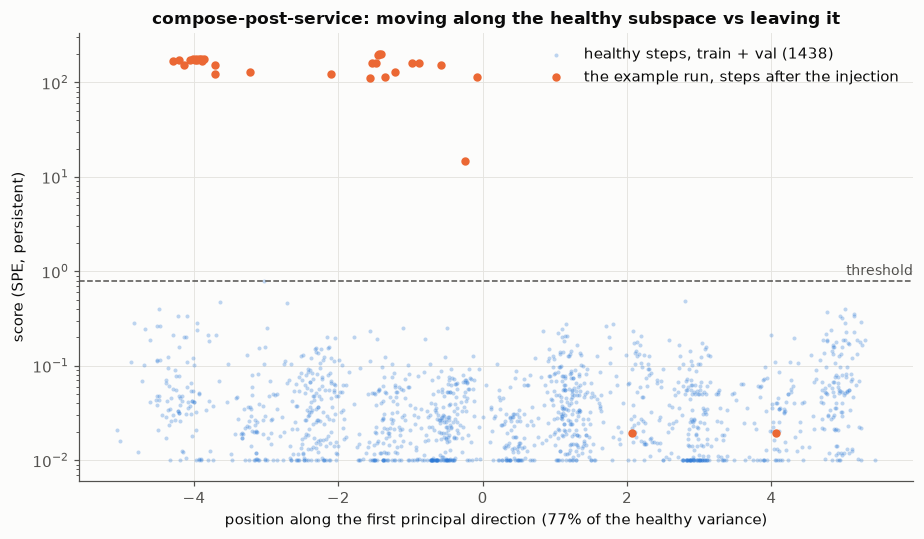

In [17]:
i, m = SVC, res.model.services[SVC]


def along(rr):
    """Position of each step along the service's first principal direction."""
    z = res.model._z(rr.P)[:, i][:, m.cols]
    return np.nan_to_num(z - m.mean) @ m.V[:, 0]


floor = 1e-2
healthy = [rr for rr in res.runs if rr.role in ("train", "val")]
x = np.concatenate([along(rr)[rr.on] for rr in healthy])
y = np.concatenate([rr.score[rr.on, i] for rr in healthy])
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(x, np.maximum(y, floor), s=7, color=BLUE, alpha=.3, lw=0, label=f"healthy steps, train + val ({len(x)})")
ax.scatter(along(r)[r.fault], np.maximum(r.score[r.fault, i], floor), s=20, color=ORANGE, zorder=3,
           label="the example run, steps after the injection")
ax.axhline(res.thr[i], color=INK2, ls="--", lw=1)
ax.text(ax.get_xlim()[1], res.thr[i] * 1.15, "threshold", color=INK2, fontsize=9, ha="right")
ax.set_yscale("log")
ax.set(xlabel=f"position along the first principal direction ({100 * m.cumulative[0]:.0f}% of the healthy variance)",
       ylabel="score (SPE, persistent)", title=f"{SERVICES[i]}: moving along the healthy subspace vs leaving it")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

## 3. Observed and expected, around the injection

**What is plotted.** Top: the feature with the largest share of the service's score after the injection, as observed (black) and as reconstructed by the PCA from the healthy subspace (dashed blue), in its real unit (memory is a change per 30 s step). Bottom: the service's score / threshold (log scale); above the dashed line the service is in alarm. The red line is the injection; the grey band is the warm-up, left out of fitting and evaluation.

**How to read it.** Before the fault the two curves overlap: the healthy subspace explains the service. When they part, the gap is the residual the score measures, and its feature is the explanation of the alarm.

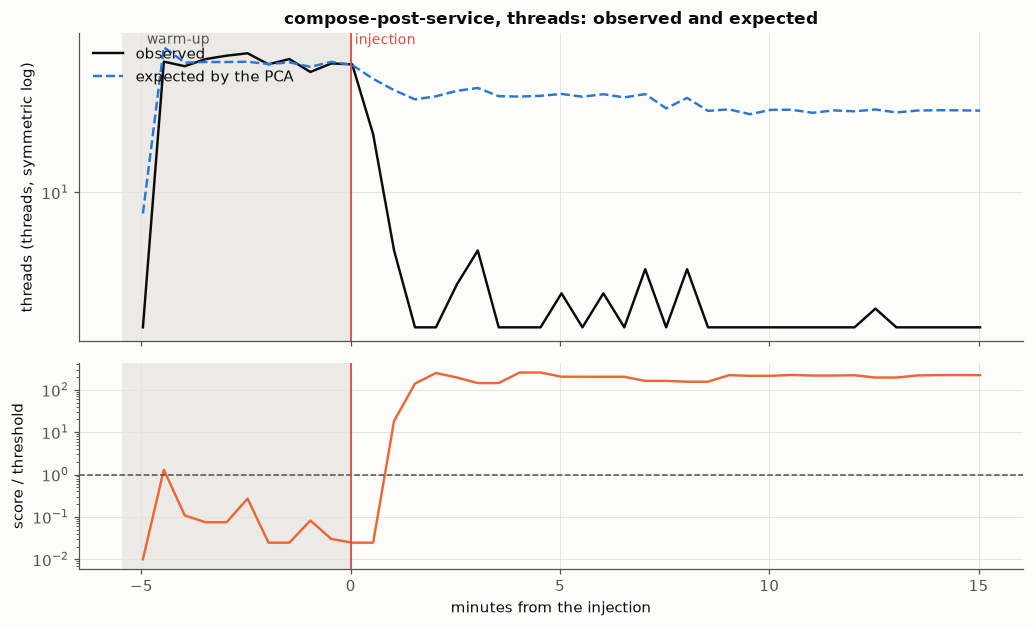

In [18]:
j = int(np.argmax(r.r2[r.fault][:, i].sum(0)))
f = FEATURES[j]
tm = minutes(r)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9.5, 5.8), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
a1.plot(tm, inputs.to_units(r.P[:, i, j], f), color=INK, lw=1.6, label="observed")
a1.plot(tm, inputs.to_units(r.expected[:, i, j], f), color=BLUE, lw=1.6, ls="--", label="expected by the PCA")
a1.set_yscale("symlog", linthresh=1)
a1.set(ylabel=f"{f} ({inputs.UNITS[f][1]}, symmetric log)", title=f"{SERVICES[i]}, {f}: observed and expected")
a1.legend(loc="upper left")
a2.plot(tm, np.maximum(r.norm[:, i], 1e-2), color=ORANGE, lw=1.6)
a2.axhline(1, color=INK2, ls="--", lw=1)
a2.set_yscale("log")
a2.set(ylabel="score / threshold", xlabel="minutes from the injection")
for a in (a1, a2):
    a.axvspan(tm[0] - .5, 0, color=GRID, alpha=.7, lw=0)
    a.axvline(0, color=RED, lw=1.2)
a1.text(tm[0], a1.get_ylim()[1], " warm-up", va="top", color=INK2, fontsize=9)
a1.text(0, a1.get_ylim()[1], " injection", va="top", color=RED, fontsize=9)
fig.tight_layout()
plt.show()

## 4. Alarm map of the run

**What is plotted.** Every service (rows) at every 30 s step (columns): colour is score / threshold on a log scale, grey at the threshold, blue below it (healthy), red above it (alarm). Crosses mark restarts, squares mark absence (the rules). The black line is the injection, the dotted line the first alarm; the hatched band is the warm-up. The target's name ends with ◀.

**How to read it.** The first red cell after the injection is the first alarm, and the ranking of figure 5 is taken at that column. When a row other than the target turns red first, the model has found the symptom on a neighbour of the faulty service: a caller, or the database the service talks to.

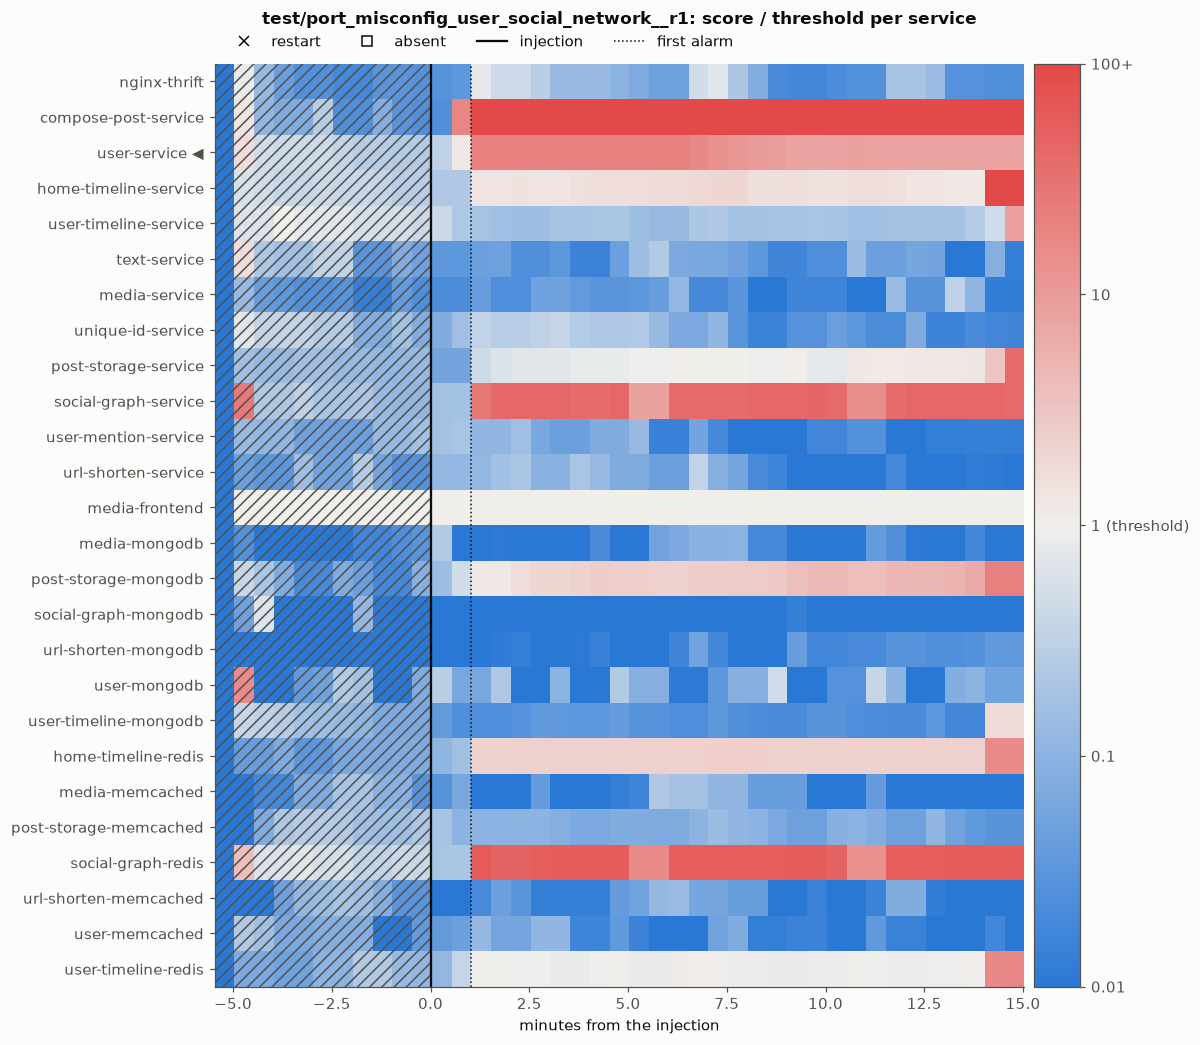

In [19]:
tm = minutes(r)
edges = np.r_[tm[0] - .5, tm]
cmap = LinearSegmentedColormap.from_list("threshold", [BLUE, NEUTRAL, RED])
fig, ax = plt.subplots(figsize=(11, .3 * len(SERVICES) + 1.8))
mesh = ax.pcolormesh(edges, np.arange(len(SERVICES) + 1), np.log10(np.clip(r.norm, 1e-2, 1e2)).T, cmap=cmap,
                     norm=TwoSlopeNorm(0, -2, 2), shading="flat")
for rule, marker in ((r.restart, "x"), (r.absent, "s")):
    tt, ss = np.where(rule & (r.on | r.fault)[:, None])
    style = {"color": INK} if marker == "x" else {"facecolors": "none", "edgecolors": INK}
    ax.scatter(tm[tt] - .25, ss + .5, marker=marker, s=22, lw=1, **style)
ax.axvspan(edges[0], 0, facecolor="none", edgecolor=INK2, hatch="///", lw=0)
ax.axvline(0, color=INK, lw=1.5)
ax.axvline(tm[k], color=INK, lw=1, ls=":")
ax.set_yticks(np.arange(len(SERVICES)) + .5, [s + (" ◀" if n in r.targets else "") for n, s in enumerate(SERVICES)])
ax.invert_yaxis()
ax.grid(False)
ax.set_xlabel("minutes from the injection")
ax.set_title(f"{EXAMPLE}: score / threshold per service", pad=26)
cb = fig.colorbar(mesh, ax=ax, ticks=[-2, -1, 0, 1, 2], pad=.01)
cb.ax.set_yticklabels(["0.01", "0.1", "1 (threshold)", "10", "100+"])
ax.legend(handles=[Line2D([], [], marker="x", ls="", color=INK, label="restart"),
                   Line2D([], [], marker="s", ls="", mfc="none", mec=INK, label="absent"),
                   Line2D([], [], color=INK, lw=1.5, label="injection"),
                   Line2D([], [], color=INK, lw=1, ls=":", label="first alarm")],
          loc="lower left", bbox_to_anchor=(0, 1.0), ncol=4)
fig.tight_layout()
plt.show()

## 5. Why each service ranks where it does

**What is plotted.** The first five services of the ranking at the first alarm, in order. Each bar splits the service's score into the shares of its feature groups (CPU, memory, threads, network); on the right, the service's score / threshold, the rule it meets if any, and its single largest feature.

**How to read it.** This is the explanation an operator would get with the alarm: which service, how far over its threshold, and which metrics moved. A service that meets a rule ranks first whatever its score; its bar can be empty, because a pod that is gone has no metrics to explain.

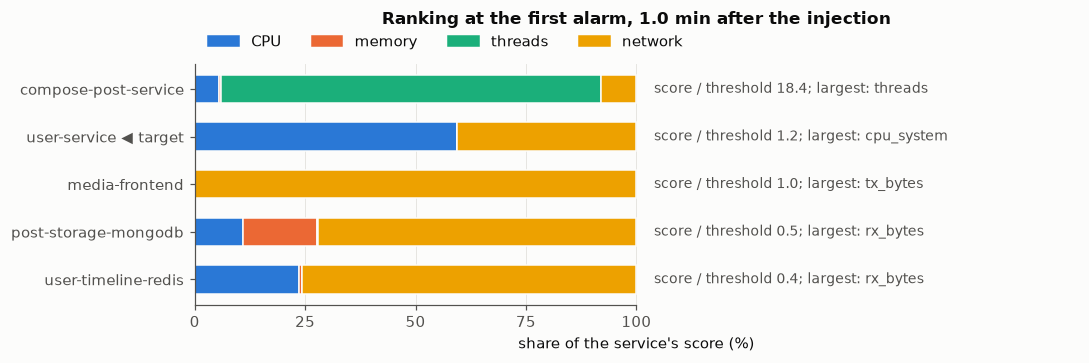

In [23]:
GROUPS = {"CPU": ("cpu_user", "cpu_system"), "memory": ("mem_working_set", "mem_rss", "mem_cache"),
          "threads": ("threads",), "network": ("rx_bytes", "tx_bytes", "rx_packets", "tx_packets")}
GROUP_COLOUR = dict(zip(GROUPS, (BLUE, ORANGE, AQUA, YELLOW)))
top = order[:5]
fig, ax = plt.subplots(figsize=(10, 3.4))
for row, s in enumerate(top):
    c = r.r2[k, s]
    left = 0.0
    for g, feats in GROUPS.items():
        share = 100 * sum(c[FEATURES.index(f)] for f in feats) / c.sum() if c.sum() else 0.0
        ax.barh(row, share, left=left, color=GROUP_COLOUR[g], height=.6, edgecolor=SURFACE, lw=1)
        left += share
    best = FEATURES[int(np.argmax(c))] if c.sum() else "none"
    ax.text(104, row, f"score / threshold {r.norm[k, s]:.1f}{ev.tags(r, k, s)}; largest: {best}", va="center",
            fontsize=9, color=INK2)
ax.set_yticks(range(len(top)), [SERVICES[s] + (" ◀ target" if s in r.targets else "") for s in top])
ax.invert_yaxis()
ax.set_xlim(0, 200)
ax.set_xticks([0, 25, 50, 75, 100])
ax.spines["bottom"].set_bounds(0, 100)
ax.grid(axis="y", visible=False)
ax.set_xlabel("share of the service's score (%)")
ax.set_title(f"Ranking at the first alarm, {minutes(r)[k]:.1f} min after the injection", pad=26)
ax.legend(handles=[Patch(color=c, label=g) for g, c in GROUP_COLOUR.items()], loc="lower left", bbox_to_anchor=(0, 1.0), ncol=4)
fig.tight_layout()
plt.show()

## 6. Healthy and fault inferences, without a threshold

**What is plotted.** Left: for every inference of the test fold, the highest score / threshold over the services, as a cumulative distribution (log scale): blue the healthy inferences (noop runs, test and test-unseen sessions, after the warm-up), orange the fault inferences. The dashed line is the threshold. Right: what happens if the threshold is multiplied by a factor c: share of healthy inferences in alarm (false-positive rate) against share of fault inferences in alarm (recall); the dot is c = 1, the protocol's threshold. Rules are left out: this is the model alone.

**How to read it.** The further apart the two curves, the better the model separates healthy from faulty steps whatever the threshold. The area under the right curve (AUC) is that separation in one number; the dot shows where the protocol's threshold sits on it.

A vertical step exactly at 1 means some service sits at its threshold at every step: a nearly constant cell whose threshold is tiny, so any blip puts it far above (in Social, media-frontend, whose network features are 0 in 98% of the training steps and whose threshold is 1.6e-5). It is never an alarm, since an alarm needs a ratio above 1, but it sets a floor under the highest ratio.

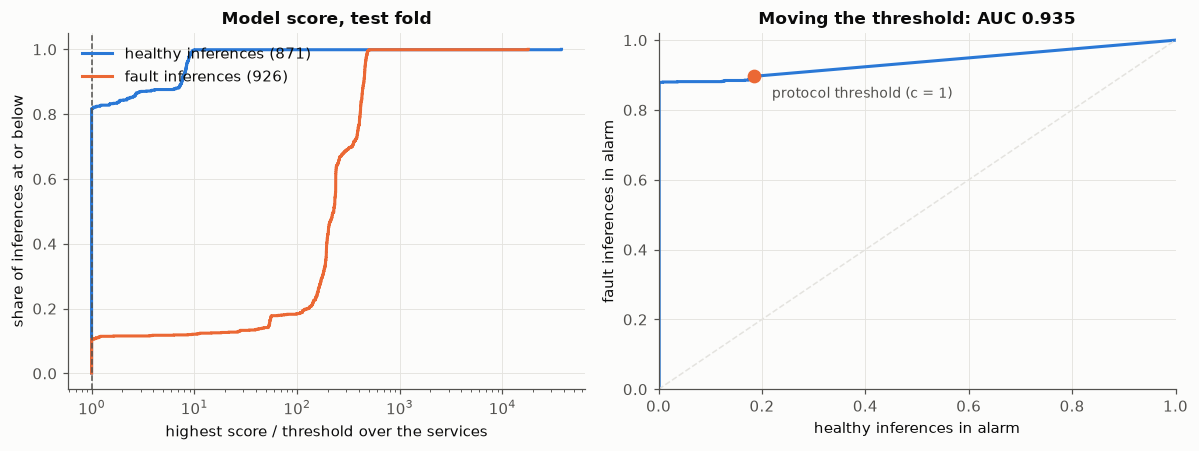

In [24]:
test = [rr for rr in res.runs if rr.fold == "test"]
h = np.concatenate([rr.norm[rr.healthy].max(1) for rr in test if rr.healthy.any()])
fl = np.concatenate([rr.norm[rr.fault].max(1) for rr in test if rr.fault.any()])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
for v, c, lab in ((h, BLUE, f"healthy inferences ({len(h)})"), (fl, ORANGE, f"fault inferences ({len(fl)})")):
    xs = np.sort(np.clip(v, 1e-2, None))
    a1.plot(xs, np.arange(1, len(xs) + 1) / len(xs), color=c, label=lab, drawstyle="steps-post")
a1.axvline(1, color=INK2, ls="--", lw=1)
a1.set_xscale("log")
a1.set(xlabel="highest score / threshold over the services", ylabel="share of inferences at or below",
       title="Model score, test fold")
a1.legend(loc="upper left")
hs, fs = np.sort(h), np.sort(fl)
cs = np.r_[0, np.unique(np.r_[hs, fs])]
fpr = 1 - np.searchsorted(hs, cs, side="right") / len(hs)
tpr = 1 - np.searchsorted(fs, cs, side="right") / len(fs)
auc = -np.trapezoid(tpr, fpr)
a2.plot(fpr, tpr, color=BLUE)
a2.plot([0, 1], [0, 1], color=GRID, ls="--", lw=1)
a2.plot((h > 1).mean(), (fl > 1).mean(), "o", color=ORANGE, ms=8)
a2.annotate("protocol threshold (c = 1)", ((h > 1).mean(), (fl > 1).mean()), xytext=(12, -14),
            textcoords="offset points", color=INK2, fontsize=9)
a2.set(xlabel="healthy inferences in alarm", ylabel="fault inferences in alarm", xlim=(0, 1), ylim=(0, 1.02),
       title=f"Moving the threshold: AUC {auc:.3f}")
fig.tight_layout()
plt.show()

## 7. Test fold, per scenario

**What is plotted.** Left: recall per inference, the share of fault inferences in alarm, for the model and its two rule variants. Right: localization of the reference system, the share of faults with an accepted target among the first 1, 3 and 5 services at the first alarm.

**How to read it.** Left says whether the system notices the fault and keeps noticing it; right says whether it points at the right place. A scenario with high recall and low top@1 is found but blamed on a neighbour (figure 4 shows which).

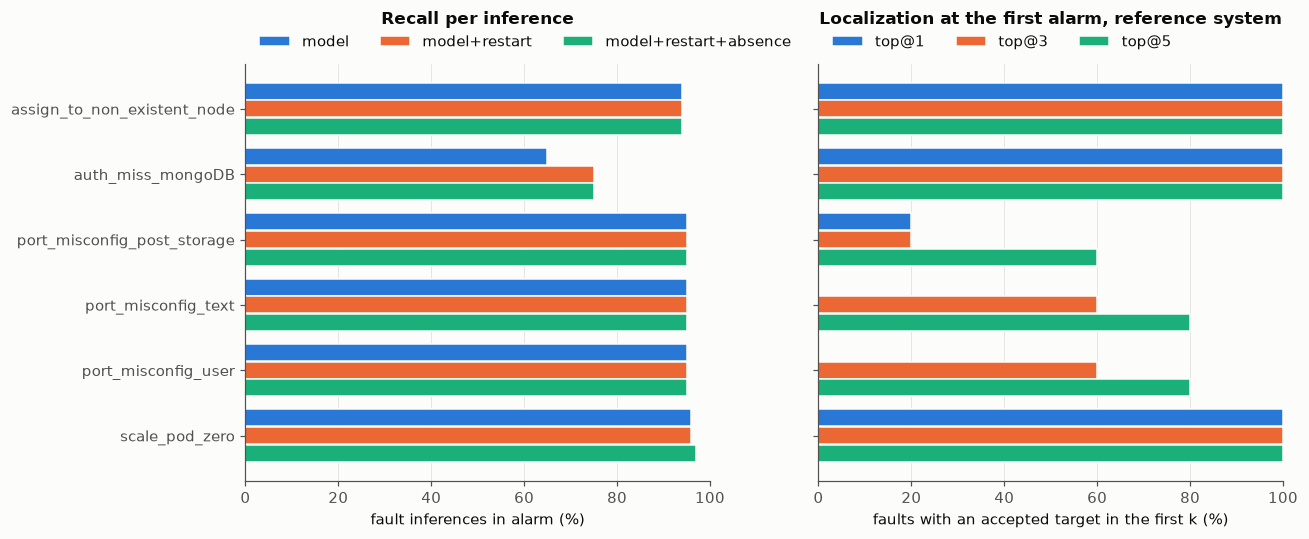

In [25]:
sc = res.scenarios.loc["test"]
names = list(sc.index)
y = np.arange(len(names))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, .5 * len(names) + 2), sharey=True)
for off, v in zip((-.27, 0, .27), ev.VARIANTS):
    a1.barh(y + off, sc[f"{v} recall"], height=.26, color=VARIANT_COLOUR[v], label=v, edgecolor=SURFACE, lw=1)
for off, n, c in zip((-.27, 0, .27), ev.TOP, (BLUE, ORANGE, AQUA)):
    a2.barh(y + off, sc[f"{FULL} top@{n}"], height=.26, color=c, label=f"top@{n}", edgecolor=SURFACE, lw=1)
a1.set_yticks(y, names)
a1.invert_yaxis()
a1.set(xlabel="fault inferences in alarm (%)", xlim=(0, 100))
a2.set(xlabel="faults with an accepted target in the first k (%)", xlim=(0, 100))
a1.set_title("Recall per inference", pad=26)
a2.set_title("Localization at the first alarm, reference system", pad=26)
for a in (a1, a2):
    a.grid(axis="y", visible=False)
    a.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3)
fig.tight_layout()
plt.show()

## 8. Test fold: false alarms and confusion matrix

**What is plotted.** Left: the share of healthy inferences in alarm, per source and variant. Right: the confusion matrix of the reference system's inferences, each cell with its count and its share of the row.

**How to read it.** The left chart does not depend on how many faults the test fold holds, so it is the false-alarm measure to quote; the right one gives precision, recall and F1 for this fold.

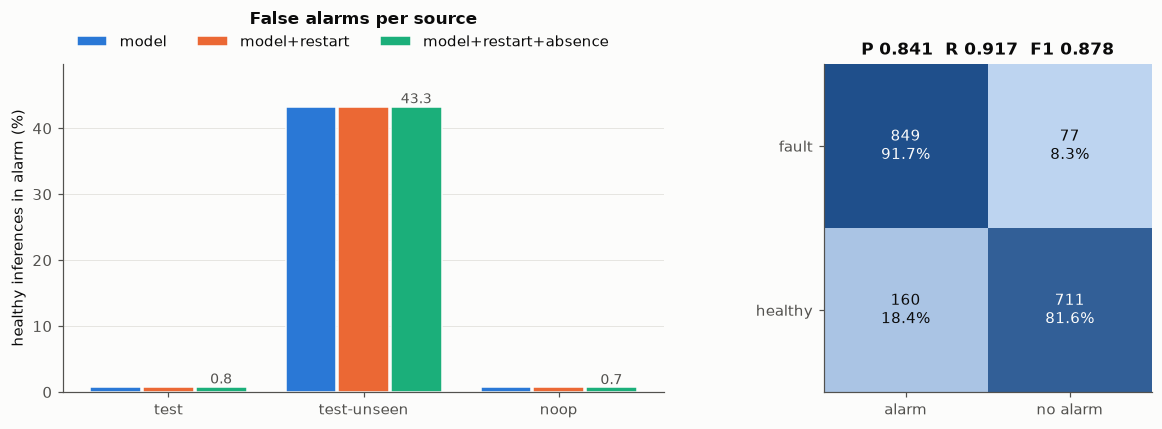

In [26]:
st = res.summary.loc["test"]
src = list(ev.SOURCES)
x = np.arange(len(src))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [3, 2]})
for off, v in zip((-.27, 0, .27), ev.VARIANTS):
    vals = [st.loc[v, f"healthy in alarm % {s}"] for s in src]
    a1.bar(x + off, vals, width=.26, color=VARIANT_COLOUR[v], label=v, edgecolor=SURFACE, lw=1)
for xx, s in zip(x, src):
    a1.text(xx + .27, st.loc[FULL, f"healthy in alarm % {s}"], f"{st.loc[FULL, f'healthy in alarm % {s}']:.1f}",
            ha="center", va="bottom", fontsize=9, color=INK2)
a1.set_xticks(x, src)
a1.grid(axis="x", visible=False)
a1.set_ylabel("healthy inferences in alarm (%)")
a1.set_ylim(0, 1.15 * max(st.loc[v, f"healthy in alarm % {s}"] for v in ev.VARIANTS for s in src))
a1.set_title("False alarms per source", pad=26)
a1.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3)
cm = st.loc[FULL, ["TP", "FN", "FP", "TN"]].astype(int).to_numpy().reshape(2, 2)
share = cm / cm.sum(1, keepdims=True)
a2.imshow(share, cmap=LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#104281"]), vmin=0, vmax=1)
for (a, b), n in np.ndenumerate(cm):
    a2.text(b, a, f"{n}\n{100 * share[a, b]:.1f}%", ha="center", va="center", color=SURFACE if share[a, b] > .5 else INK)
a2.set_xticks([0, 1], ["alarm", "no alarm"])
a2.set_yticks([0, 1], ["fault", "healthy"])
a2.grid(False)
a2.set_title(f"P {st.loc[FULL, 'precision']:.3f}  R {st.loc[FULL, 'recall']:.3f}  F1 {st.loc[FULL, 'F1']:.3f}")
fig.tight_layout()
plt.show()

## The numbers behind the figures

The test rows of `summary.csv` for this app, one column per variant.

In [27]:
res.summary.loc["test"].T

variant,model,model+restart,model+restart+absence
fault inferences,926.000,926.000,926.000
healthy inferences,871.000,871.000,871.000
TP,830.000,846.000,849.000
FN,96.000,80.000,77.000
FP,160.000,160.000,160.000
TN,711.000,711.000,711.000
precision,0.838,0.841,0.841
recall,0.896,0.914,0.917
F1,0.866,0.876,0.878
F0.5,0.849,0.855,0.856
